# Oppgave 4 – TSM-kart (HYPSO-2 vs. Sentinel-3 OLCI)

Steg:
1. Les inn `tsm(yoc)` + lat/lon fra begge filene (via `felles.py`)
2. Masker ugyldige piksler (land, sky, flagg)
3. Beskjær Sentinel-3 til området HYPSO-2 dekker
4. Plott begge kartene side ved side i samme projeksjon og med felles fargeskala
5. Enkel statistikk til tolkningen

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning, module="shapely")  # ufarlige cartopy-advarsler

import felles  # egne funksjoner: innlesing, maskering, beskjæring

# Felles fargeskala for TSM [g m^-3] (log-skala)
VMIN, VMAX = 0.1, 20

## 1–3. Les inn, masker og beskjær

In [2]:
lat_h2, lon_h2, tsm_h2, flagg_h2 = felles.les_produkt(felles.FIL_H2, "tsm(yoc)")
lat_s3, lon_s3, tsm_s3, flagg_s3 = felles.les_produkt(felles.FIL_S3, "tsm(yoc)")

# Fjern land, sky, flaggede piksler og ekstreme verdier
tsm_h2 = felles.masker(tsm_h2, flagg_h2)
tsm_s3 = felles.masker(tsm_s3, flagg_s3)

# Beskjær Sentinel-3 til HYPSO-2-omrisset
kant_lon, kant_lat = felles.hypso_omriss(lat_h2, lon_h2)
lat_s3c, lon_s3c, tsm_s3c = felles.beskjaer_til_hypso(lat_s3, lon_s3, tsm_s3, kant_lon, kant_lat)

print(f"Gyldige piksler HYPSO-2: {np.isfinite(tsm_h2).sum()},  Sentinel-3 (beskåret): {np.isfinite(tsm_s3c).sum()}")

Gyldige piksler HYPSO-2: 122253,  Sentinel-3 (beskåret): 219664


## 4. Kart side ved side

- Projeksjon: UTM sone 33N (EPSG:32633), samme for begge
- Felles log-fargeskala `VMIN`–`VMAX`
- Samme kartutsnitt (havområdet i HYPSO-2-scenen) i begge panelene
- Grått = ingen gyldige data, stiplet linje = omrisset av HYPSO-2-bildet

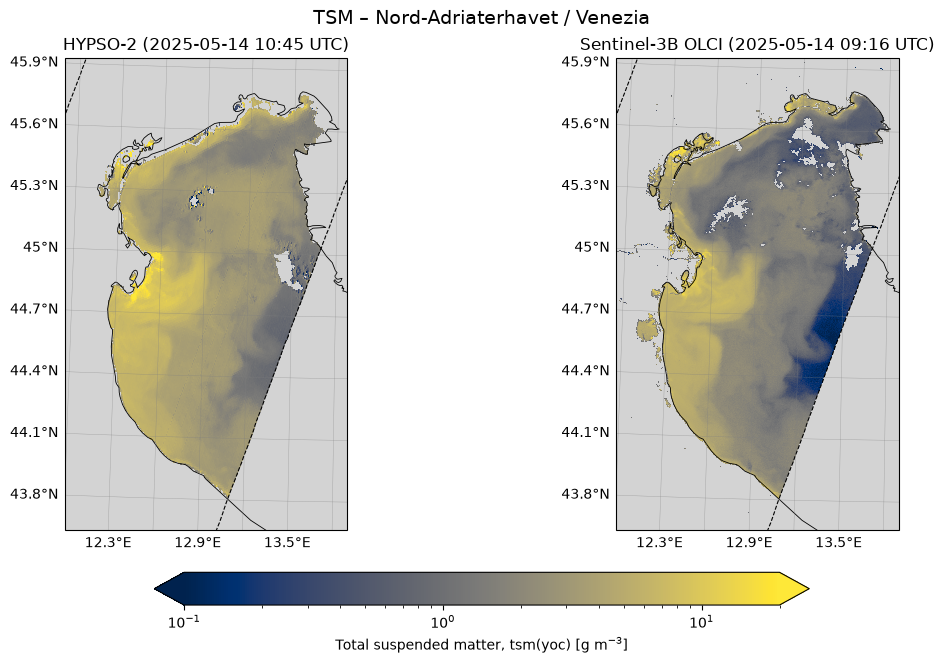

In [3]:
proj = ccrs.UTM(zone=33)          # kartprojeksjon (CRS) for plottet
data_crs = ccrs.PlateCarree()     # dataene er i vanlige lat/lon-grader
norm = LogNorm(vmin=VMIN, vmax=VMAX)

# Kartutsnitt: zoom inn på havområdet med gyldige HYPSO-data (+ litt marg)
gyldig = np.isfinite(tsm_h2)
marg = 0.15
utsnitt = [lon_h2[gyldig].min() - marg, lon_h2[gyldig].max() + marg,
           lat_h2[gyldig].min() - marg, lat_h2[gyldig].max() + marg]

fig, akser = plt.subplots(1, 2, figsize=(11, 6.5), subplot_kw={"projection": proj},
                          constrained_layout=True)

for ax, lon, lat, tsm, tittel in [
    (akser[0], lon_h2, lat_h2, tsm_h2, "HYPSO-2 (2025-05-14 10:45 UTC)"),
    (akser[1], lon_s3c, lat_s3c, tsm_s3c, "Sentinel-3B OLCI (2025-05-14 09:16 UTC)"),
]:
    bilde = ax.pcolormesh(lon, lat, tsm, transform=data_crs, norm=norm,
                          cmap="cividis", shading="auto")
    ax.plot(kant_lon, kant_lat, transform=data_crs, color="k", lw=0.8, ls="--")  # HYPSO-omriss
    ax.set_facecolor("lightgray")  # grått = ingen data (land, sky, utenfor sporet)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.6)
    ax.set_extent(utsnitt, crs=data_crs)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6)
    gl.top_labels = gl.right_labels = False
    ax.set_title(tittel)

# Én felles fargebar med enhet
cbar = fig.colorbar(bilde, ax=akser, orientation="horizontal", shrink=0.6, pad=0.04, extend="both")
cbar.set_label("Total suspended matter, tsm(yoc) [g m$^{-3}$]")

fig.suptitle("TSM – Nord-Adriaterhavet / Venezia", fontsize=14)
fig.savefig("oppgave4_tsm_kart.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Statistikk (hjelp til tolkningen)

Sammenligner fordelingen av TSM innenfor samme område for de to sensorene.

HYPSO-2      n= 122253  median= 3.28  5%= 1.13  95%= 8.29  snitt= 3.91 g m^-3
Sentinel-3   n= 219664  median= 1.73  5%= 0.30  95%= 6.22  snitt= 2.48 g m^-3


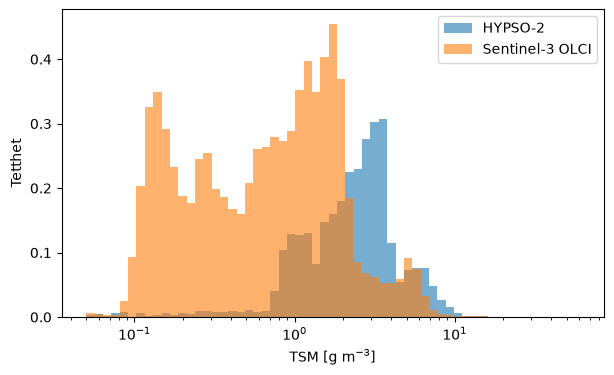

In [4]:
def stats(navn, data):
    v = data[np.isfinite(data)]
    p5, p50, p95 = np.percentile(v, [5, 50, 95])
    print(f"{navn:12s} n={v.size:7d}  median={p50:5.2f}  5%={p5:5.2f}  95%={p95:5.2f}  "
          f"snitt={v.mean():5.2f} g m^-3")

stats("HYPSO-2", tsm_h2)
stats("Sentinel-3", tsm_s3c)

# Histogram på log-skala
bins = np.logspace(np.log10(VMIN / 2), np.log10(VMAX * 3), 60)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(tsm_h2[np.isfinite(tsm_h2)], bins=bins, density=True, alpha=0.6, label="HYPSO-2")
ax.hist(tsm_s3c[np.isfinite(tsm_s3c)], bins=bins, density=True, alpha=0.6, label="Sentinel-3 OLCI")
ax.set_xscale("log")
ax.set_xlabel("TSM [g m$^{-3}$]")
ax.set_ylabel("Tetthet")
ax.legend()
plt.show()

## Answers for the report (Task 4)

Both maps use a common logarithmic colour scale of 0.1–20 g m⁻³ (equivalent to mg L⁻¹).
This covers clear offshore water (<1 g m⁻³) as well as the sediment-laden Po plume (>10 g m⁻³).
OLCI was cropped to the HYPSO-2 footprint (dashed outline), and only unflagged pixels are shown.

**Similarities.** The two TSM maps agree better than the Chl-a maps.
Both show the highest TSM at the Po delta mouths and in a coastal band along the Italian coast south of the delta, decreasing towards the central Adriatic.
The plume shape, the filaments extending offshore at about 44.7–44.9°N and the clearer water along the eastern edge of the swath appear in the same positions in both maps.
Unlike for Chl-a, HYPSO-2 clearly resolves the plume in TSM.
This shows that HYPSO-2 does capture the plume signal, but the signal is not translated into the blue/green ratio that the Chl-a algorithm relies on.

**Differences.** HYPSO-2 gives systematically higher TSM.
The median is 3.3 g m⁻³ for HYPSO-2 and 1.7 g m⁻³ for OLCI, and the 5–95 % range is 1.1–8.3 vs. 0.3–6.2 g m⁻³.
The relative difference is largest in clear water, where OLCI drops to about 0.2 g m⁻³ while HYPSO-2 stays above about 0.7 g m⁻³.

**Possible causes.**
TSM algorithms are based on reflectance in the green–red part of the spectrum, where particle backscattering dominates the water-leaving signal.
At the same locations, HYPSO-2 Rrs(665) is about 2.5–3× higher than OLCI's (Task 3, section 6).
A positive offset in HYPSO-2 Rrs therefore translates directly into higher TSM.
This is consistent with residual atmospheric-correction or calibration bias, which matters most in clear water, where the true red signal is close to zero.
Other contributing factors are the 1.5 h time difference (tidal and plume dynamics near the delta) and the different spatial and spectral resolution of the two sensors.
Since the algorithm was not regionally tuned for the Adriatic, neither absolute value can be verified without in-situ measurements.